# Remove an object

## Imports

In [1]:
%matplotlib widget

from utils import * 
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve #solve Ax = b

## Load a video

In [2]:
nb_frames = len(os.listdir(FRAMES_dir))

#all frames and masks in arrays
frames = np.stack([load_frame(i) for i in range(nb_frames)])
masks = np.stack([load_mask(i) for i in range(nb_frames)])

print(frames.shape)
print(masks.shape)

(100, 240, 360, 3)
(100, 240, 360)


## Enlarge the mask

SAM2 gives tight masks, along the edge there remain some blurred pixels not included in the mask 

cv2.dilate : a pixel becomes white if at least one neighbor in the square is white

(<Figure size 1000x300 with 3 Axes>,
 array([[<Axes: title={'center': 'frame'}>,
         <Axes: title={'center': 'SAM 2 mask'}>,
         <Axes: title={'center': 'new bigger mask'}>]], dtype=object))

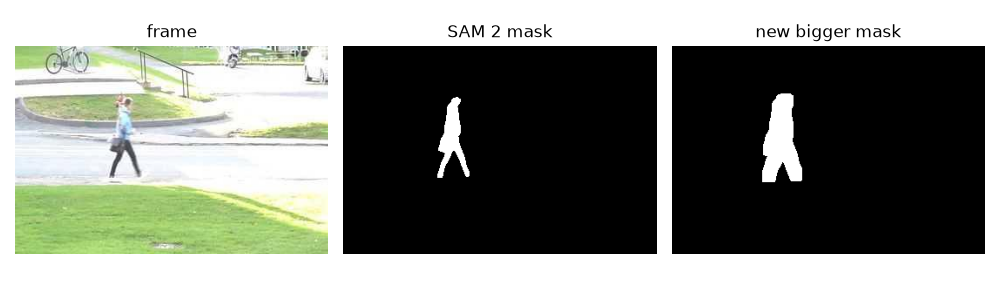

In [3]:
def dilate_mask(mask, size=10) : 
    #size = how much bigger in pixels
    kernel = np.ones((size, size), np.uint8)
    return cv2.dilate(mask.astype(np.uint8), kernel) > 0 

masks_big = np.stack([dilate_mask(m) for m in masks])


#test 
imshow([frames[50], masks[50]*255, masks_big[50]*255], ["frame", "SAM 2 mask", "new bigger mask"], figsize=(10,3))

## Method 1 : fill the gap by extending surrounding pixels

no way of knowing what is actually behind the gap

-> cv2.inpaint

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'inpaint'}>]], dtype=object))

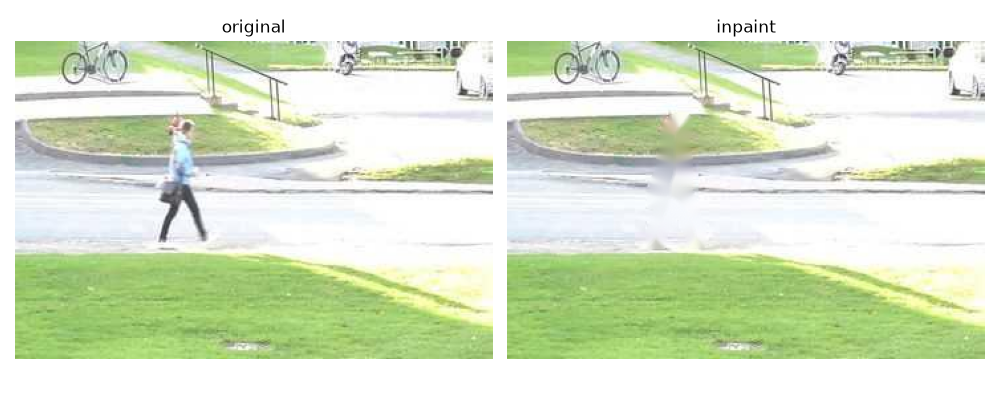

In [4]:
def remove_inpaint(frame, mask):
    hole = mask.astype(np.uint8)*255 
    return cv2.inpaint(frame, hole, 3, cv2.INPAINT_TELEA)

res_inpaint = remove_inpaint(frames[50], masks_big[50])
imshow([frames[50], res_inpaint], ["original", "inpaint"])

## Method 2  : median in time 

each pixel is visible without the object present 
for every pixel, we calculate the median of its color values over time

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'frame'}>,
         <Axes: title={'center': 'background plate'}>]], dtype=object))

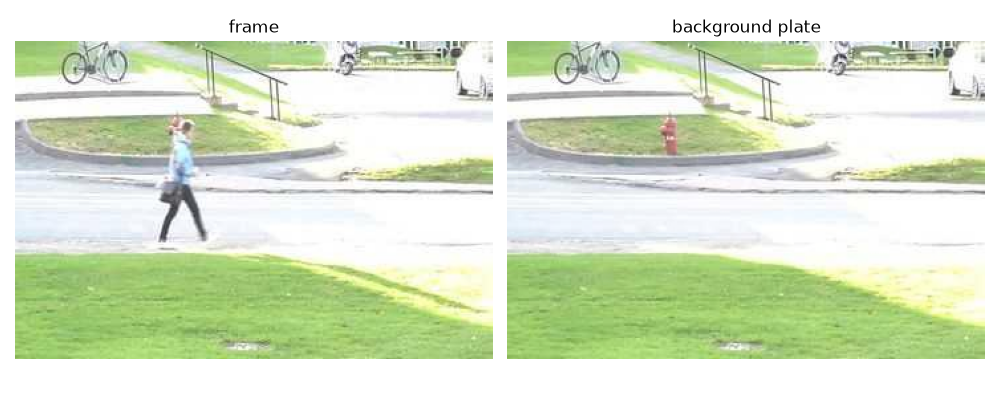

In [5]:
def background_plate(frames, masks) : 
    #median of each pixel over time (ignore pixels hidden by the object)
    all_frames = frames.astype(np.float32)
    
    #pixels hidden by the object -> NaN
    all_frames[masks] = np.nan 

    #median over time (ignoring NaN), axis = 0 -> time
    #np.nanmedian : median that ignores NaN
    median_frame = np.nanmedian(all_frames, axis=0, overwrite_input=True)

    #pixels hidden in all frames are still NaN (never seen)
    hole_mask = np.isnan(median_frame).any(axis=2).astype(np.uint8) * 255

    #NaN -> 0, back to a normal image
    #np.nan_to_num : replace nan by 0
    uint8_frame = np.nan_to_num(median_frame).astype(np.uint8) 

    #fill never seen pixels with inpainting 
    filled = cv2.inpaint(uint8_frame, hole_mask, 3, cv2.INPAINT_TELEA)
    return filled 

bg = background_plate(frames, masks_big)
imshow([frames[50], bg], ["frame", "background plate"])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'median'}>]], dtype=object))

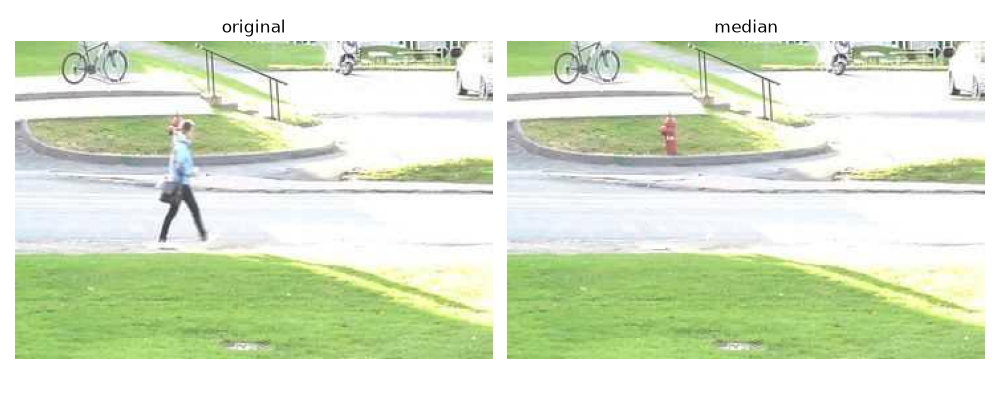

In [6]:
# for each frame 

def remove_object(frame, mask, bg) : 
    #replace the object pixels with the background plate pixels
    res = frame.copy()
    res[mask] = bg[mask]
    return res

res_median = remove_object(frames[50], masks_big[50], bg)
imshow([frames[50], res_median], ["original", "median"])

## Method 3 : nearest neighboring frame

we take each pixel from a frame that is close temporally, where the object is not present 

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'nearest'}>]], dtype=object))

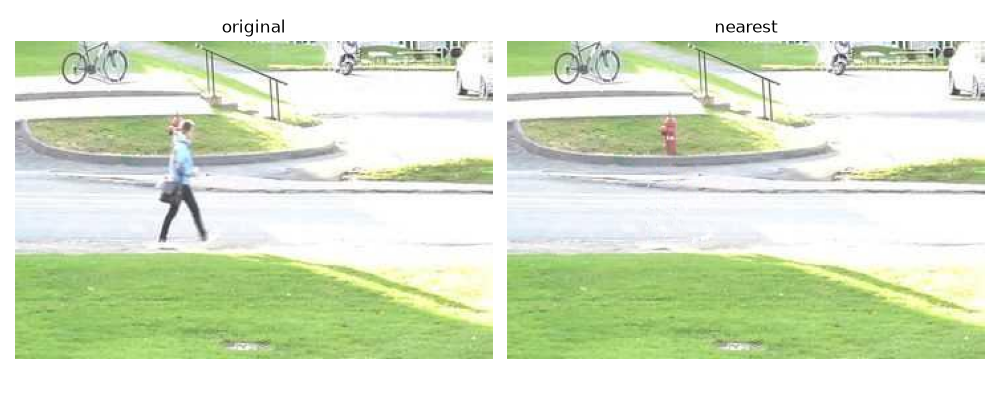

In [9]:
#for each hidden pixel we want to seek for a close image where the pixel was visible
def remove_nearest(frames, masks, i):
    res = frames[i].copy()

    #pixels still to fill
    to_fill = masks[i].copy()
    n = len(frames)

    #moving progressively further 
    for d in range(1,n):
        for j in (i-d, i+d) : 
            if 0 <= j < n : #existing frame
                #pixels that are still to fill & not hidden anymore
                ok = to_fill & ~masks[j]
                
                res[ok] = frames[j][ok]
                #remove it from the list
                to_fill = to_fill & ~ok 
        if not to_fill.any():
            break 

    if to_fill.any(): 
        res = remove_inpaint(res, to_fill)
    return res 

res_nearest = remove_nearest(frames, masks_big, 50)
imshow([frames[50], res_nearest], ["original", "nearest"])


## Method 4 : A x = b (Poisson)

idea : copy the gradients (color changes) of the background, not its values

-> gradients not enough, we need a starting point (pixels around the hole known)

-> 2D : hole surrounded on all sides, we can't respect all the gradients and all the edges perfectly

-> best compromise : one equation per pixel

-> Ax = b, each equation contains the pixel and its neighbors, one system to solve (spsolve)


(<Figure size 1000x300 with 3 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'poisson no guide'}>,
         <Axes: title={'center': 'poisson guide'}>]], dtype=object))

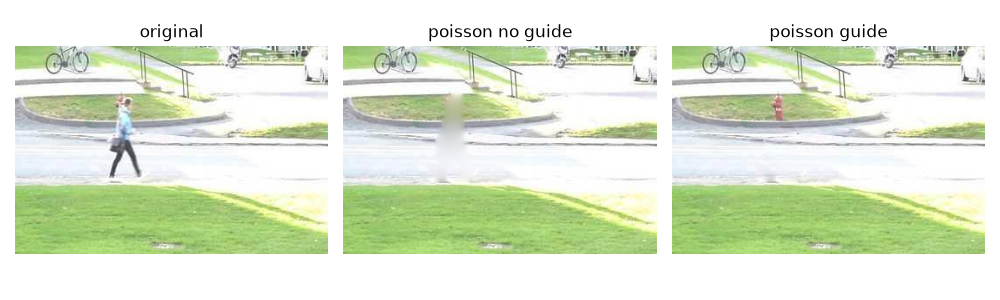

In [10]:
def remove_poisson(frame, mask, guide=None):
    #guide = background image (computed before)

    height, width = mask.shape 

    #hole to fill 
    #a. give nb to hole pixels, each pixel of the hole is an unknown : x0, x1 ...

    ys, xs = np.nonzero(mask) #pos of all pixels in the hole
    n = len(ys)

    #each pixel of the hole have a nb : 0, 1, 2,...
    nb = np.full((height, width), -1)
    nb[ys, xs] = np.arange(n) 

    #b. variations, for each pixel : 4 * me - 4 neighbors 
    
    if guide is None : 
        #no guide => smooth fill
        guide_changes = np.zeros((height, width, 3))
    else : 
        #compute variations 
        kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], np.float64)

        #slide the kernel
        guide_changes = cv2.filter2D(guide.astype(np.float64), -1, kernel, borderType=cv2.BORDER_REPLICATE)

    #c. write one equation per pixel of the hole
    #equation : (nb of neighbors) * me - unknown neighbors = known neihbors + variation of background

    #nxn : k-th line = equation of pixel k
    A = lil_matrix((n,n))
    b = guide_changes[ys, xs] #background variations 

    for k in range(n): 
        y, x = ys[k], xs[k]

        #4 neighbors
        for yn, xn in [(y-1, x), (y+1, x), (y, x-1), (y,x+1)]:
            #ignore neighbors outside 
            if 0 <= yn < height and 0 <= xn < width : 
                A[k,k] += 1

                if mask[yn, xn] : 
                    #neighbor also in the hole 
                    A[k, nb[yn, xn]] = -1

                else : 
                    b[k] += frame[yn, xn]

    #d. solve 
    x = spsolve(A.tocsr(), b)

    res = frame.copy()
    res[ys, xs] = np.clip(x, 0, 255).astype(np.uint8)
    return res


#no guide
res_poisson = remove_poisson(frames[50], masks_big[50])

#guide
res_poisson_guide = remove_poisson(frames[50], masks_big[50], guide = bg)


imshow([frames[50], res_poisson, res_poisson_guide], ["original", "poisson no guide", "poisson guide"], figsize=(10, 3))

## Handle shadow

## Comparison

(<Figure size 1000x300 with 6 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'inpaint'}>,
         <Axes: title={'center': 'median'}>,
         <Axes: title={'center': 'nearest'}>,
         <Axes: title={'center': 'poisson'}>,
         <Axes: title={'center': 'poisson with guide'}>]], dtype=object))

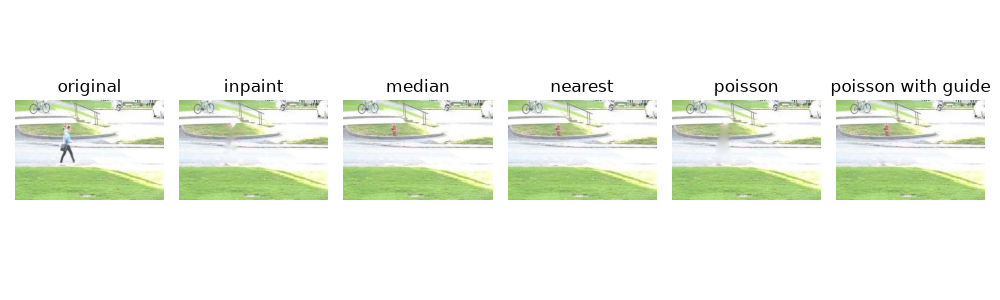

In [11]:
res = [frames[50], res_inpaint, res_median, res_nearest, res_poisson, res_poisson_guide]
titles = ["original", "inpaint", "median", "nearest", "poisson", "poisson with guide"]
imshow(res, titles, figsize=(10, 3))

## Evaluate methods

## Video

video saved


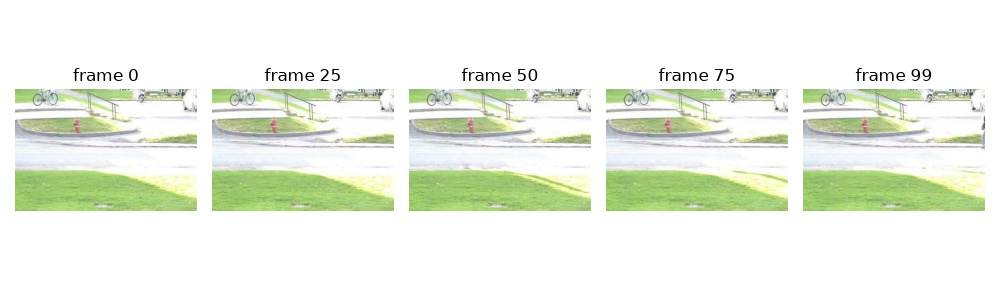

In [12]:
def remove_object_from_video(frames, masks, bg, method="poisson") : 
    removed_frames = []
    for i in range(len(frames)) : 
        mask = masks[i] 
        if method == "median" : 
            res = remove_object(frames[i], mask, bg)
        elif method == "nearest" : 
            res = remove_nearest(frames, masks, i)
        else : 
            res = remove_poisson(frames[i], mask, guide=bg)
        
        removed_frames.append(res) 
    return removed_frames

METHOD = "poisson"

removed_frames = remove_object_from_video(frames, masks_big, bg, method=METHOD)

#check some frames
check = [0, nb_frames // 4, nb_frames // 2, 3 * nb_frames // 4, nb_frames - 1]
imshow([removed_frames[k] for k in check], [f"frame {k}" for k in check], figsize=(10, 3))

os.makedirs(OUTPUTS_dir, exist_ok=True)
save_video(removed_frames, f"{OUTPUTS_dir}/removed_{METHOD}.mp4", fps=30)
print("video saved")